<a href="https://colab.research.google.com/github/nc307337/Gen-Ai-Practical-No-04-Image-Generation-using-Deep-Convolutional-GAN-DCGAN-/blob/main/Gen_Ai_Assignment_2_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q diffusers transformers accelerate safetensors

In [2]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

from torch.utils.data import DataLoader
from torchvision.utils import make_grid, save_image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Please enable GPU from Runtime > Change runtime type.")

Device: cpu
Please enable GPU from Runtime > Change runtime type.


In [4]:
transform = transforms.ToTensor()

train_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

class_names = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Classes:", class_names)

Training images: 60000
Testing images: 10000
Classes: ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


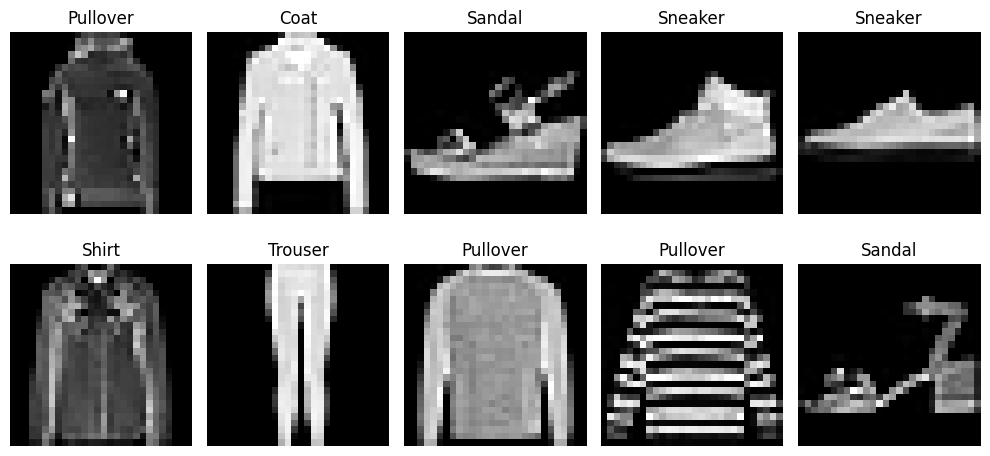

In [5]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(class_names[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 28 * 28),
            nn.Sigmoid(),
            nn.Unflatten(1, (1, 28, 28))
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded


ae = Autoencoder().to(device)

criterion = nn.MSELoss()
optimizer_ae = optim.Adam(ae.parameters(), lr=0.001)

print(ae)

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
    (4): Unflatten(dim=1, unflattened_size=(1, 28, 28))
  )
)


In [7]:
AE_EPOCHS = 10
ae_losses = []

for epoch in range(AE_EPOCHS):
    ae.train()
    running_loss = 0

    for images, _ in train_loader:
        images = images.to(device)

        optimizer_ae.zero_grad()

        outputs = ae(images)
        loss = criterion(outputs, images)

        loss.backward()
        optimizer_ae.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    ae_losses.append(epoch_loss)

    print(f"Epoch [{epoch+1}/{AE_EPOCHS}] Loss: {epoch_loss:.6f}")

Epoch [1/10] Loss: 0.033445
Epoch [2/10] Loss: 0.017301
Epoch [3/10] Loss: 0.014636
Epoch [4/10] Loss: 0.013233
Epoch [5/10] Loss: 0.012253
Epoch [6/10] Loss: 0.011494
Epoch [7/10] Loss: 0.010961
Epoch [8/10] Loss: 0.010445
Epoch [9/10] Loss: 0.010034
Epoch [10/10] Loss: 0.009694


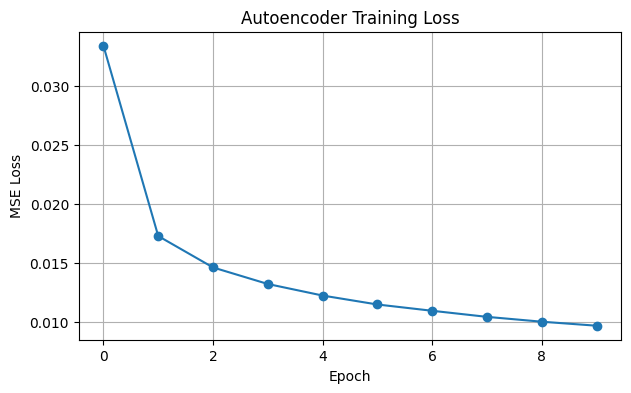

In [8]:
plt.figure(figsize=(7, 4))
plt.plot(ae_losses, marker="o")
plt.title("Autoencoder Training Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.grid()
plt.show()

Cell 8 – Display original and reconstructed images



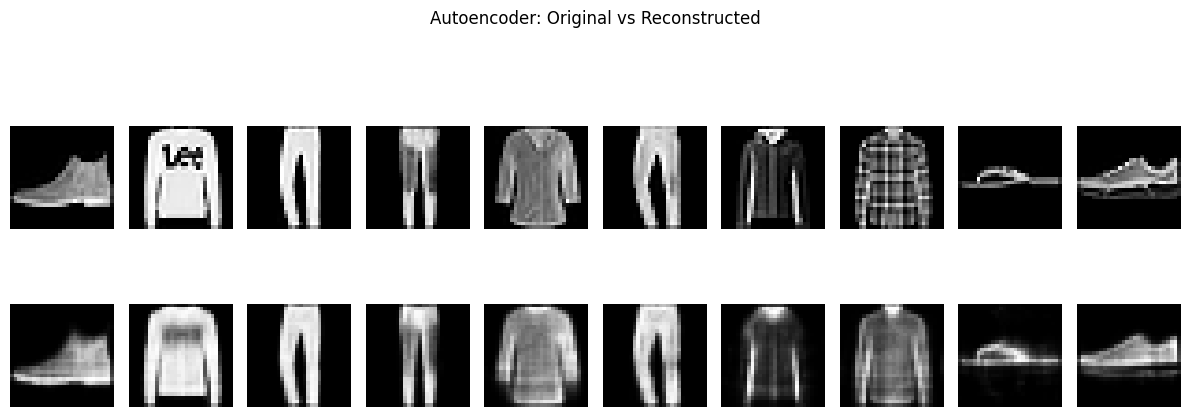

In [9]:
ae.eval()

images, labels = next(iter(test_loader))
sample_images = images[:10].to(device)

with torch.no_grad():
    reconstructed = ae(sample_images)

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(sample_images[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Original")

    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Reconstructed")

plt.suptitle("Autoencoder: Original vs Reconstructed")
plt.tight_layout()
plt.show()

Part 4: Variational Autoencoder (VAE)
Aim: Learn a probabilistic latent representation and reconstruct fashion images.

Cell 9 – Define VAE

In [10]:
class VAE(nn.Module):
    def __init__(self, latent_dim=20):
        super().__init__()

        self.fc1 = nn.Linear(784, 400)
        self.fc_mu = nn.Linear(400, latent_dim)
        self.fc_logvar = nn.Linear(400, latent_dim)

        self.fc2 = nn.Linear(latent_dim, 400)
        self.fc3 = nn.Linear(400, 784)

    def encode(self, x):
        x = x.view(-1, 784)
        hidden = torch.relu(self.fc1(x))

        mu = self.fc_mu(hidden)
        logvar = self.fc_logvar(hidden)

        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        hidden = torch.relu(self.fc2(z))
        return torch.sigmoid(self.fc3(hidden)).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstructed = self.decode(z)

        return reconstructed, mu, logvar


vae = VAE(latent_dim=20).to(device)
optimizer_vae = optim.Adam(vae.parameters(), lr=0.001)

print(vae)

VAE(
  (fc1): Linear(in_features=784, out_features=400, bias=True)
  (fc_mu): Linear(in_features=400, out_features=20, bias=True)
  (fc_logvar): Linear(in_features=400, out_features=20, bias=True)
  (fc2): Linear(in_features=20, out_features=400, bias=True)
  (fc3): Linear(in_features=400, out_features=784, bias=True)
)


Cell 10 – VAE loss function

In [11]:
def vae_loss_function(reconstructed, original, mu, logvar):
    reconstruction_loss = nn.functional.binary_cross_entropy(
        reconstructed, original, reduction="sum"
    )

    kl_divergence = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return reconstruction_loss + kl_divergence

Cell 11 – Train VAE

In [12]:
VAE_EPOCHS = 10
vae_losses = []

for epoch in range(VAE_EPOCHS):
    vae.train()
    running_loss = 0

    for images, _ in train_loader:
        images = images.to(device)

        optimizer_vae.zero_grad()

        reconstructed, mu, logvar = vae(images)

        loss = vae_loss_function(
            reconstructed, images, mu, logvar
        )

        loss.backward()
        optimizer_vae.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_dataset)
    vae_losses.append(epoch_loss)

    print(f"Epoch [{epoch+1}/{VAE_EPOCHS}] Loss: {epoch_loss:.4f}")

Epoch [1/10] Loss: 284.6279
Epoch [2/10] Loss: 255.9601
Epoch [3/10] Loss: 250.3892
Epoch [4/10] Loss: 247.6008
Epoch [5/10] Loss: 245.9753
Epoch [6/10] Loss: 244.8483
Epoch [7/10] Loss: 244.0439
Epoch [8/10] Loss: 243.3736
Epoch [9/10] Loss: 242.8652
Epoch [10/10] Loss: 242.4306


Cell 12 – Plot VAE loss

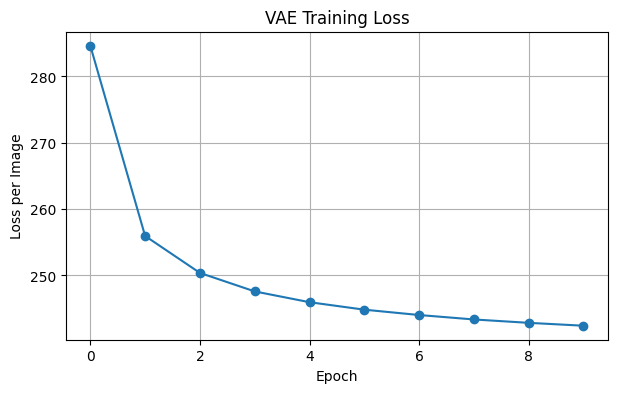

In [13]:
plt.figure(figsize=(7, 4))
plt.plot(vae_losses, marker="o")
plt.title("VAE Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss per Image")
plt.grid()
plt.show()


Cell 13 – Original vs reconstructed images

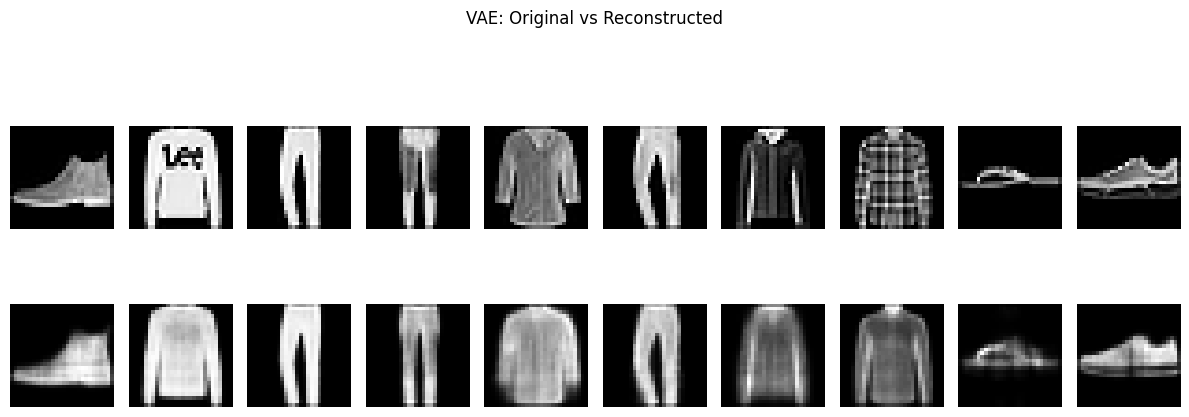

In [14]:
vae.eval()

images, labels = next(iter(test_loader))
sample_images = images[:10].to(device)

with torch.no_grad():
    reconstructed, mu, logvar = vae(sample_images)

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(sample_images[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Original")

    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("VAE Output")

plt.suptitle("VAE: Original vs Reconstructed")
plt.tight_layout()
plt.show()

Part 5: DCGAN
Aim: Train a Generator and Discriminator to generate new fashion images.

Cell 14 – Prepare DCGAN dataset

DCGAN generator uses Tanh, so images must be normalized to the range [-1, 1].

In [15]:
dcgan_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

dcgan_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=dcgan_transform
)

dcgan_loader = DataLoader(
    dcgan_dataset,
    batch_size=128,
    shuffle=True,
    drop_last=True
)

Cell 15 – Define Generator

In [16]:
LATENT_DIM = 100

class Generator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(LATENT_DIM, 128 * 7 * 7),
            nn.BatchNorm1d(128 * 7 * 7),
            nn.ReLU(True),
            nn.Unflatten(1, (128, 7, 7)),

            nn.ConvTranspose2d(128, 64, 4, 2, 1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(64, 1, 4, 2, 1),
            nn.Tanh()
        )

    def forward(self, z):
        return self.model(z)


generator = Generator().to(device)

Cell 16 – Define Discriminator

In [17]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, 4, 2, 1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)


discriminator = Discriminator().to(device)

print(generator)
print(discriminator)

Generator(
  (model): Sequential(
    (0): Linear(in_features=100, out_features=6272, bias=True)
    (1): BatchNorm1d(6272, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Unflatten(dim=1, unflattened_size=(128, 7, 7))
    (4): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (8): Tanh()
  )
)
Discriminator(
  (model): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Flatten(start_dim=1, end_dim

Cell 17 – Train DCGAN

In [18]:
GAN_EPOCHS = 10

criterion_gan = nn.BCELoss()

optimizer_G = optim.Adam(
    generator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

g_losses = []
d_losses = []

for epoch in range(GAN_EPOCHS):

    generator.train()
    discriminator.train()

    total_g_loss = 0
    total_d_loss = 0

    for real_images, _ in dcgan_loader:
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        real_labels = torch.ones(batch_size, 1, device=device)
        fake_labels = torch.zeros(batch_size, 1, device=device)

        # Train Discriminator
        optimizer_D.zero_grad()

        real_output = discriminator(real_images)
        real_loss = criterion_gan(real_output, real_labels)

        noise = torch.randn(batch_size, LATENT_DIM, device=device)
        fake_images = generator(noise)

        fake_output = discriminator(fake_images.detach())
        fake_loss = criterion_gan(fake_output, fake_labels)

        d_loss = real_loss + fake_loss
        d_loss.backward()
        optimizer_D.step()

        # Train Generator
        optimizer_G.zero_grad()

        noise = torch.randn(batch_size, LATENT_DIM, device=device)
        generated_images = generator(noise)

        output = discriminator(generated_images)
        g_loss = criterion_gan(output, real_labels)

        g_loss.backward()
        optimizer_G.step()

        total_g_loss += g_loss.item()
        total_d_loss += d_loss.item()

    avg_g = total_g_loss / len(dcgan_loader)
    avg_d = total_d_loss / len(dcgan_loader)

    g_losses.append(avg_g)
    d_losses.append(avg_d)

    print(
        f"Epoch [{epoch+1}/{GAN_EPOCHS}] "
        f"Generator Loss: {avg_g:.4f} | "
        f"Discriminator Loss: {avg_d:.4f}"
    )

Epoch [1/10] Generator Loss: 3.2531 | Discriminator Loss: 0.2418
Epoch [2/10] Generator Loss: 2.9538 | Discriminator Loss: 0.2567
Epoch [3/10] Generator Loss: 2.8007 | Discriminator Loss: 0.2920
Epoch [4/10] Generator Loss: 2.3565 | Discriminator Loss: 0.4355
Epoch [5/10] Generator Loss: 2.1163 | Discriminator Loss: 0.5022
Epoch [6/10] Generator Loss: 2.0393 | Discriminator Loss: 0.5255
Epoch [7/10] Generator Loss: 2.0118 | Discriminator Loss: 0.5433
Epoch [8/10] Generator Loss: 2.0129 | Discriminator Loss: 0.5522
Epoch [9/10] Generator Loss: 2.0466 | Discriminator Loss: 0.5431
Epoch [10/10] Generator Loss: 2.0480 | Discriminator Loss: 0.5526


Cell 18 – Plot DCGAN losses

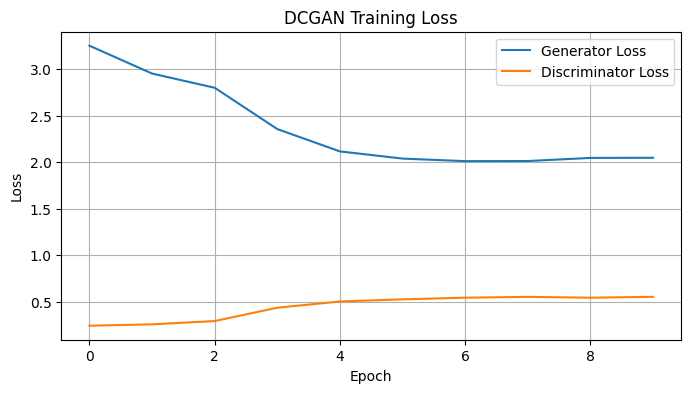

In [19]:
plt.figure(figsize=(8, 4))

plt.plot(g_losses, label="Generator Loss")
plt.plot(d_losses, label="Discriminator Loss")

plt.title("DCGAN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

Cell 19 – Generate 64 new fashion images

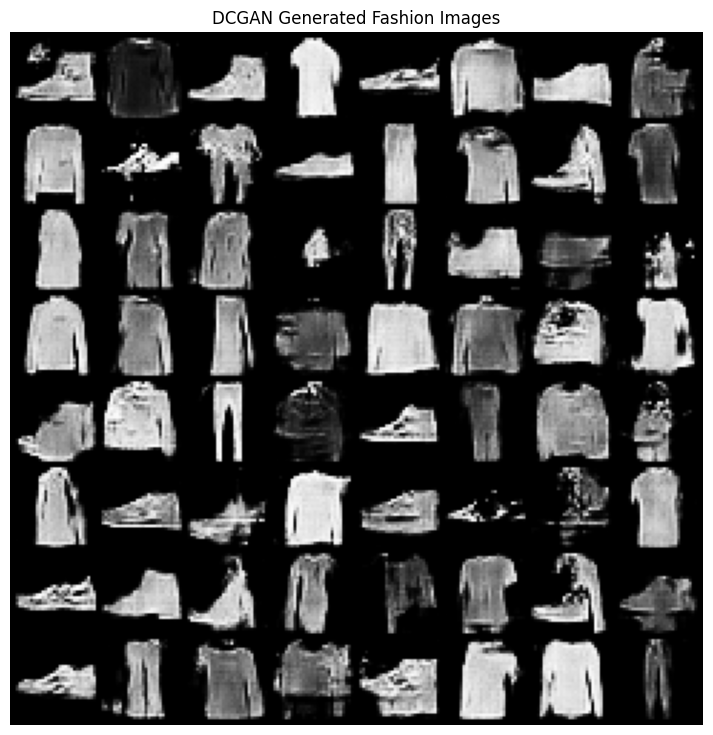

In [22]:
generator.eval()

with torch.no_grad():
    noise = torch.randn(64, LATENT_DIM, device=device)
    generated_images = generator(noise)

# Convert images from [-1, 1] to [0, 1]
generated_images = (generated_images + 1) / 2

# Create image grid
grid = make_grid(
    generated_images.cpu(),
    nrow=8,
    normalize=False,
    padding=2
)

# Convert (C, H, W) to (H, W, C)
grid = grid.permute(1, 2, 0).numpy()

# Display generated images
plt.figure(figsize=(9, 9))
plt.imshow(grid)
plt.title("DCGAN Generated Fashion Images")
plt.axis("off")
plt.show()

Part 6: Stable Diffusion v1.5
Aim: Generate fashion-related images using text prompts.

Important: Stable Diffusion is a pretrained text-to-image model. It will use text prompts; it is not trained on Fashion-MNIST in this practical.

Cell 20 – Load Stable Diffusion

In [ ]:
from diffusers import StableDiffusionPipeline
import torch

model_id = "runwayml/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    safety_checker=None
)

pipe = pipe.to("cuda")

# Reduce memory usage
pipe.enable_attention_slicing()

print("Stable Diffusion loaded successfully!")

Cell 21 – Generate fashion images

In [ ]:
prompts = [
    "A realistic red sports sneaker, professional product photography, white background",
    "A blue denim jacket displayed on a mannequin, fashion photography",
    "A black leather handbag, luxury product photography, studio lighting",
    "A pair of modern white running shoes, clean product photography"
]

sd_images = []

for i, prompt in enumerate(prompts):

    print(f"Generating image {i+1}: {prompt}")

    result = pipe(
        prompt,
        num_inference_steps=20,
        guidance_scale=7.0,
        height=512,
        width=512
    )

    image = result.images[0]
    sd_images.append(image)

    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.title(f"Stable Diffusion Output {i+1}")
    plt.axis("off")
    plt.show()

Cell 22 – Save Stable Diffusion images

In [ ]:
os.makedirs("fashion_outputs", exist_ok=True)

for i, image in enumerate(sd_images):
    image.save(f"fashion_outputs/stable_diffusion_{i+1}.png")

print("Stable Diffusion images saved!")

Part 7: Compare AE and VAE reconstruction
Cell 23 – Calculate test MSE

In [ ]:
def calculate_mse(model, test_loader, model_type):
    model.eval()
    total_squared_error = 0
    total_pixels = 0

    with torch.no_grad():
        for images, _ in test_loader:
            images = images.to(device)

            if model_type == "AE":
                outputs = model(images)
            else:
                outputs, _, _ = model(images)

            total_squared_error += torch.sum(
                (outputs - images) ** 2
            ).item()

            total_pixels += images.numel()

    return total_squared_error / total_pixels


ae_mse = calculate_mse(ae, test_loader, "AE")
vae_mse = calculate_mse(vae, test_loader, "VAE")

print("Autoencoder Test MSE:", round(ae_mse, 6))
print("VAE Test MSE:", round(vae_mse, 6))

Cell 24 – Compare reconstruction results

In [ ]:
models = ["Autoencoder", "VAE"]
mse_values = [ae_mse, vae_mse]

plt.figure(figsize=(7, 4))
plt.bar(models, mse_values)
plt.title("AE vs VAE Reconstruction MSE")
plt.ylabel("Test MSE")
plt.show()

for name, value in zip(models, mse_values):
    print(f"{name}: {value:.6f}")

Part 8: Save all models and outputs
Cell 25 – Save trained models

In [ ]:
os.makedirs("fashion_outputs", exist_ok=True)

torch.save(ae.state_dict(), "fashion_outputs/autoencoder.pth")
torch.save(vae.state_dict(), "fashion_outputs/vae.pth")
torch.save(generator.state_dict(), "fashion_outputs/dcgan_generator.pth")
torch.save(discriminator.state_dict(), "fashion_outputs/dcgan_discriminator.pth")

print("All trained models saved successfully!")

Cell 26 – Download output folder as ZIP

In [ ]:
import shutil
from google.colab import files

shutil.make_archive(
    "fashion_mnist_assignment_outputs",
    "zip",
    "fashion_outputs"
)

files.download("fashion_mnist_assignment_outputs.zip")